<a href="https://colab.research.google.com/github/naylaviona/Studi-Kasus-Informatics-Practitioner-Lecture-Series/blob/main/StudiKasus2(WORAWAN_DIAZ_CARBALLO).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STUDI KASUS 2: BRIDGING GLOBAL INFRASTRUCTURE TO ADDRESS LOCAL CHALLENGE WITH HPC
# PEMATERI: WORAWAN DIAZ CARBALLO

## Judul Studi Kasus: Prediksi Kualitas Udara (PM 2.5) di Wilayah Bengkulu Berdasarkan Data Cuaca Lokal Menggunakan Machine Learning

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import os

In [ ]:
# --- LANGKAH 1: MEMBUAT DATA DUMMY ---
# Menentukan jumlah baris data buatan (misal: 200 baris data harian)
jumlah_data = 200

# Mengatur random seed agar hasil data dummy selalu konsisten setiap kali dijalankan
np.random.seed(42)

# Membuat data tiruan untuk wilayah Bengkulu
data_dummy = {
    'suhu': np.random.uniform(24.0, 34.0, jumlah_data),          # Suhu antara 24°C - 34°C
    'kelembaban': np.random.uniform(60.0, 95.0, jumlah_data),    # Kelembaban 60% - 95%
    'kecepatan_angin': np.random.uniform(1.0, 15.0, jumlah_data),# Kecepatan angin 1 - 15 km/h
}

# Membuat target 'pm25' (dibuat ada korelasi logis: suhu & angin tinggi biasanya PM2.5 lebih rendah)
data_dummy['pm25'] = (
    50
    - (data_dummy['suhu'] * 0.8)
    - (data_dummy['kecepatan_angin'] * 1.2)
    + (data_dummy['kelembaban'] * 0.3)
    + np.random.normal(0, 3, jumlah_data) # Menambahkan sedikit noise/variasi acak
)

# Ubah ke dalam format DataFrame Pandas
df = pd.DataFrame(data_dummy)

print("--- 5 Baris Pertama Data Dummy ---")
print(df.head())
print("-" * 40)

--- 5 Baris Pertama Data Dummy ---
        suhu  kelembaban  kecepatan_angin       pm25
0  27.745401   82.471108         2.443734  48.021757
1  33.507143   62.944899        13.635741  23.336248
2  31.319939   65.657005         8.073533  34.631819
3  29.986585   91.449397        12.570405  35.255339
4  25.560186   81.225017         5.480694  45.681575
----------------------------------------


In [ ]:
# Memisahkan fitur (X) dan target prediksi (y)
X = df[['suhu', 'kelembaban', 'kecepatan_angin']]
y = df['pm25']

In [ ]:
# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# 2. MODELING (Integrator task)
# Melatih model Random Forest
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
# 3. EVALUATION
# Memprediksi data test
predictions = model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
print(f"Mean Squared Error: {mse}")

Mean Squared Error: 9.426280301325338


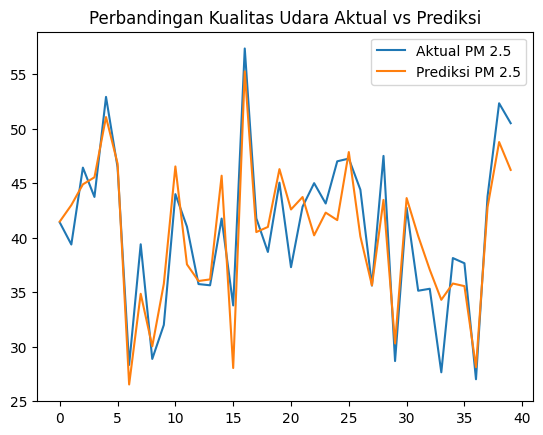

In [ ]:
# Visualisasi Hasil
plt.plot(y_test.values, label='Aktual PM 2.5')
plt.plot(predictions, label='Prediksi PM 2.5')
plt.legend()
plt.title("Perbandingan Kualitas Udara Aktual vs Prediksi")
plt.show()